Dataset Shape: (4653, 9)

--- Data Types & Missing Values ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4653 entries, 0 to 4652
Data columns (total 9 columns):
 #   Column                     Non-Null Count  Dtype 
---  ------                     --------------  ----- 
 0   Education                  4653 non-null   object
 1   JoiningYear                4653 non-null   int64 
 2   City                       4653 non-null   object
 3   PaymentTier                4653 non-null   int64 
 4   Age                        4653 non-null   int64 
 5   Gender                     4653 non-null   object
 6   EverBenched                4653 non-null   object
 7   ExperienceInCurrentDomain  4653 non-null   int64 
 8   LeaveOrNot                 4653 non-null   int64 
dtypes: int64(5), object(4)
memory usage: 327.3+ KB
None

--- Summary Statistics ---
       JoiningYear  PaymentTier          Age  ExperienceInCurrentDomain  \
count  4653.000000  4653.000000  4653.000000                4653.00

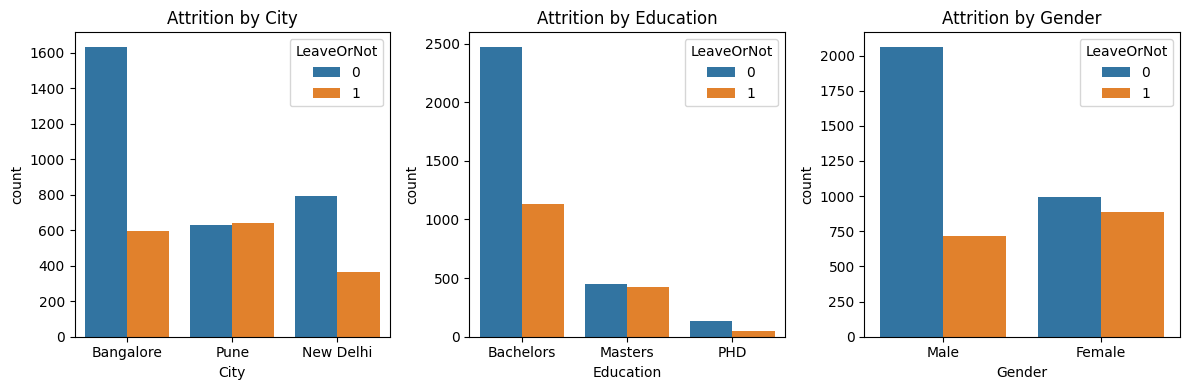

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset
df = pd.read_csv('/Employee.csv')

# 1. Basic Exploration
print("Dataset Shape:", df.shape)
print("\n--- Data Types & Missing Values ---")
print(df.info())

print("\n--- Summary Statistics ---")
print(df.describe())

print("\n--- Target Class Distribution ---")
print(df['LeaveOrNot'].value_counts(normalize=True) * 100)

# 2. Visualizations
plt.figure(figsize=(12, 4))

# Attrition by City
plt.subplot(1, 3, 1)
sns.countplot(data=df, x='City', hue='LeaveOrNot')
plt.title('Attrition by City')

# Attrition by Education
plt.subplot(1, 3, 2)
sns.countplot(data=df, x='Education', hue='LeaveOrNot')
plt.title('Attrition by Education')

# Attrition by Gender
plt.subplot(1, 3, 3)
sns.countplot(data=df, x='Gender', hue='LeaveOrNot')
plt.title('Attrition by Gender')

plt.tight_layout()
plt.show()

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Separate features (X) and target (y)
X = df.drop(columns=['LeaveOrNot'])
y = df['LeaveOrNot']

# Identify column types
numerical_cols = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_cols = X.select_dtypes(include=['object', 'category']).columns.tolist()

print("Numerical features:", numerical_cols)
print("Categorical features:", categorical_cols)

# Train-test split (80% train, 20% test, stratified to maintain class balance)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Build preprocessing pipeline
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_cols)
    ]
)

print(f"Training set shape: {X_train.shape}")
print(f"Test set shape: {X_test.shape}")

Numerical features: ['JoiningYear', 'PaymentTier', 'Age', 'ExperienceInCurrentDomain']
Categorical features: ['Education', 'City', 'Gender', 'EverBenched']
Training set shape: (3722, 8)
Test set shape: (931, 8)


In [5]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix, classification_report
)

# Function to evaluate models
def evaluate_model(name, model, X_test, y_test):
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    print(f"=== {name} Performance ===")
    print(f"Accuracy:  {accuracy_score(y_test, y_pred):.4f}")
    print(f"Precision: {precision_score(y_test, y_pred):.4f}")
    print(f"Recall:    {recall_score(y_test, y_pred):.4f}")
    print(f"F1-Score:  {f1_score(y_test, y_pred):.4f}")
    print(f"ROC-AUC:   {roc_auc_score(y_test, y_prob):.4f}")
    print("\nConfusion Matrix:")
    print(confusion_matrix(y_test, y_pred))
    print("-" * 40)

# 1. Logistic Regression Model
lr_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(random_state=42))
])
lr_pipeline.fit(X_train, y_train)
evaluate_model("Logistic Regression", lr_pipeline, X_test, y_test)

# 2. Random Forest Model
rf_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(random_state=42, n_estimators=100))
])
rf_pipeline.fit(X_train, y_train)
evaluate_model("Random Forest", rf_pipeline, X_test, y_test)

=== Logistic Regression Performance ===
Accuracy:  0.7551
Precision: 0.7212
Recall:    0.4688
F1-Score:  0.5682
ROC-AUC:   0.7403

Confusion Matrix:
[[553  58]
 [170 150]]
----------------------------------------
=== Random Forest Performance ===
Accuracy:  0.8346
Precision: 0.8242
Recall:    0.6594
F1-Score:  0.7326
ROC-AUC:   0.8609

Confusion Matrix:
[[566  45]
 [109 211]]
----------------------------------------


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [6]:
import joblib
import json

# Select Random Forest as the best model
best_model = rf_pipeline

# Extract feature importances
cat_encoder = best_model.named_steps['preprocessor'].named_transformers_['cat']
encoded_cat_cols = cat_encoder.get_feature_names_out(categorical_cols).tolist()
all_features = numerical_cols + encoded_cat_cols

importances = best_model.named_steps['classifier'].feature_importances_
feature_imp_df = pd.DataFrame({'Feature': all_features, 'Importance': importances})
feature_imp_df = feature_imp_df.sort_values(by='Importance', ascending=False)

print("Top Features Driving Attrition:")
print(feature_imp_df.head(10))

# Save the pipeline
model_filename = 'pipeline.pkl'
joblib.dump(best_model, model_filename)
print(f"\nModel pipeline successfully saved to {model_filename}")

# Optional: Download model file directly to your local computer from Colab
from google.colab import files
files.download(model_filename)

Top Features Driving Attrition:
                      Feature  Importance
0                 JoiningYear    0.343711
2                         Age    0.177671
1                 PaymentTier    0.092441
3   ExperienceInCurrentDomain    0.087732
9                   City_Pune    0.060285
5           Education_Masters    0.050608
4         Education_Bachelors    0.040884
10              Gender_Female    0.037011
11                Gender_Male    0.035216
8              City_New Delhi    0.025756

Model pipeline successfully saved to pipeline.pkl


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>